In [16]:
from google.colab import files

uploaded = files.upload()

Saving diabetes.csv to diabetes (1).csv


In [17]:
import pandas as pd

df = pd.read_csv('diabetes.csv')

print(df.shape)
display(df.head())

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
df = pd.read_csv('diabetes.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [20]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [21]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate Records:
0


Outcome
0    500
1    268
Name: count, dtype: int64


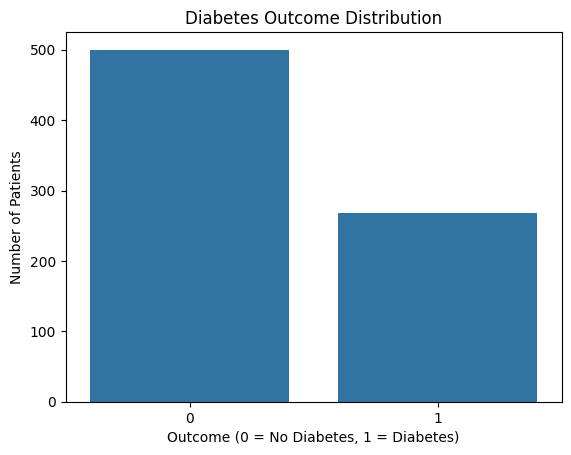

In [22]:
print(df['Outcome'].value_counts())

sns.countplot(data=df, x='Outcome')
plt.title('Diabetes Outcome Distribution')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Number of Patients')
plt.show()

In [23]:
# Check invalid zero values in medical columns

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

for column in columns_to_check:
    zero_count = (df[column] == 0).sum()
    print(f"{column}: {zero_count} zero values")

Glucose: 5 zero values
BloodPressure: 35 zero values
SkinThickness: 227 zero values
Insulin: 374 zero values
BMI: 11 zero values


In [24]:
# Replace invalid zero values with NaN

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_to_check] = df[columns_to_check].replace(0, np.nan)

print("Invalid zero values converted to NaN!")

print("\nMissing values after replacement:")
print(df.isnull().sum())

Invalid zero values converted to NaN!

Missing values after replacement:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [25]:
# Handle missing values using median imputation

for column in columns_to_check:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)

print("Missing values handled successfully!")

print("\nMissing values after imputation:")
print(df.isnull().sum())

Missing values handled successfully!

Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [26]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Remove duplicates if found
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Total Duplicate Records: 0
Dataset Shape After Removing Duplicates: (768, 9)


In [27]:
# Outlier detection using IQR

numerical_columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
]

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} potential outliers")

Pregnancies: 4 potential outliers
Glucose: 0 potential outliers
BloodPressure: 14 potential outliers
SkinThickness: 87 potential outliers
Insulin: 346 potential outliers
BMI: 8 potential outliers
DiabetesPedigreeFunction: 29 potential outliers
Age: 9 potential outliers


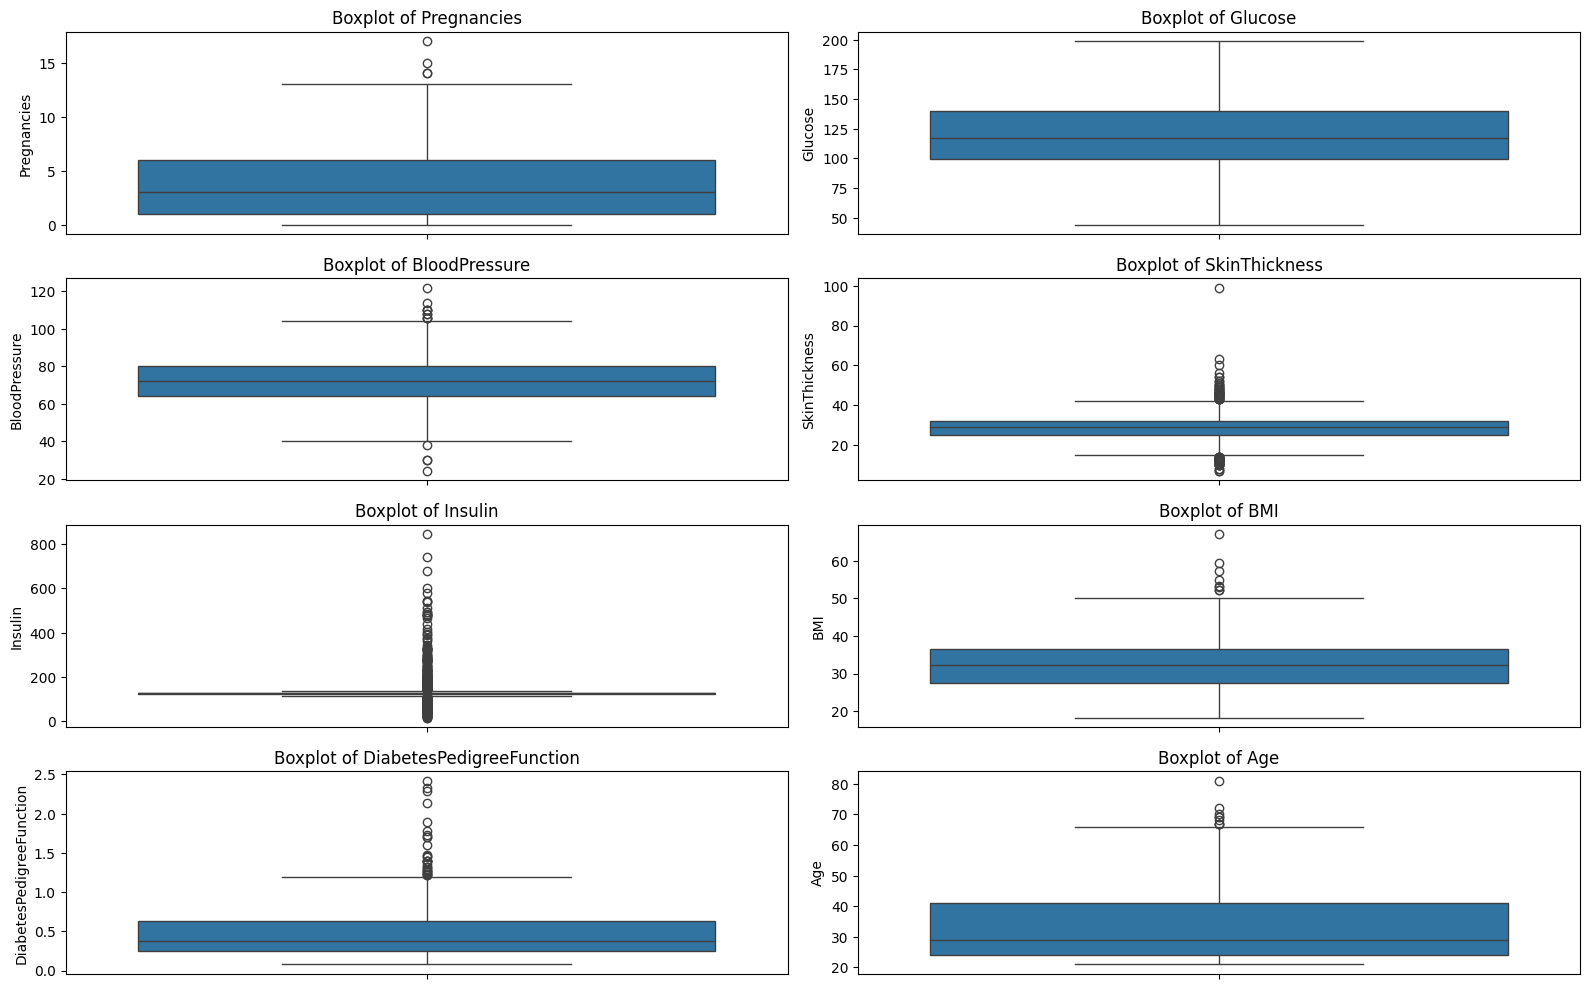

In [28]:
# Visualize outliers using boxplots

plt.figure(figsize=(16, 10))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(4, 2, i)

    sns.boxplot(y=df[column])
    plt.title(f'Boxplot of {column}')
    plt.ylabel(column)

plt.tight_layout()
plt.show()

In [29]:
# Reload original dataset
df = pd.read_csv('diabetes.csv')

# Convert invalid zero values into NaN
columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_to_check] = df[columns_to_check].replace(0, np.nan)

# Remove duplicate records
df = df.drop_duplicates()

# Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (768, 8)
Target shape: (768,)

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (614, 8)
Testing Features: (154, 8)
Training Target: (614,)
Testing Target: (154,)


In [31]:
# Import required libraries

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create preprocessing and classification pipeline

logistic_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Logistic Regression Pipeline Created Successfully!")

print("\nPipeline Steps:")
print(logistic_model)


Logistic Regression Pipeline Created Successfully!

Pipeline Steps:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])


In [32]:
# Train Logistic Regression Model

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

# Generate predictions
y_pred = logistic_model.predict(X_test)

print("\nModel Predictions:")
print(y_pred[:10])

Logistic Regression Model Trained Successfully!

Model Predictions:
[1 0 0 0 0 0 0 1 0 1]


In [33]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate performance metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("LOGISTIC REGRESSION MODEL PERFORMANCE")
print("-------------------------------------")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

LOGISTIC REGRESSION MODEL PERFORMANCE
-------------------------------------
Accuracy:  0.7078
Precision: 0.6000
Recall:    0.5000
F1 Score:  0.5455

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



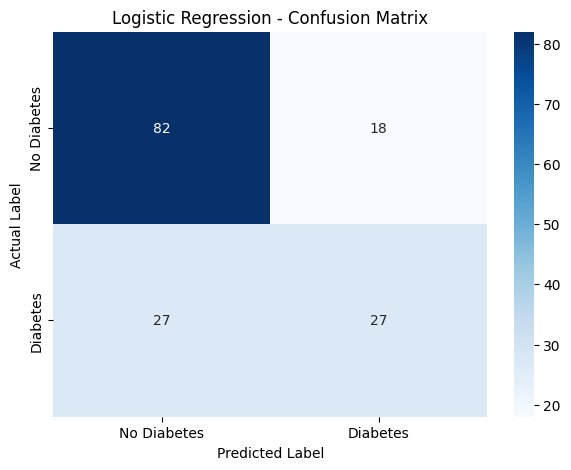

In [34]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

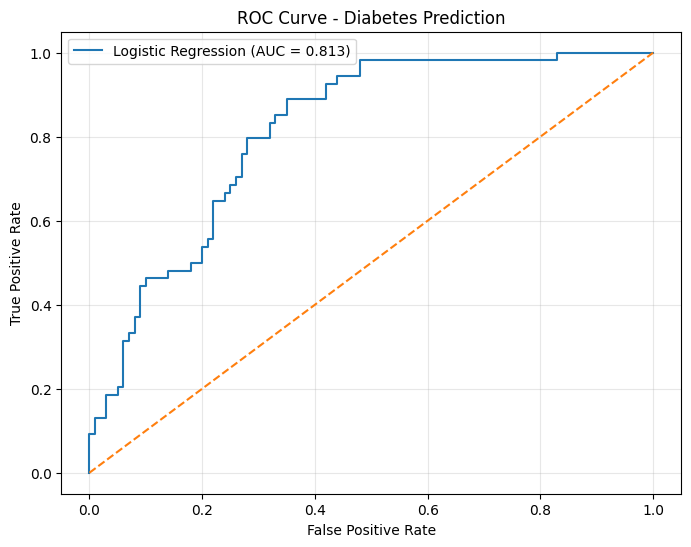

ROC-AUC Score: 0.813


In [35]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - Diabetes Prediction')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

FEATURE IMPORTANCE ANALYSIS
                    Feature  Importance
1                   Glucose    0.159907
5                       BMI    0.030907
0               Pregnancies    0.026111
6  DiabetesPedigreeFunction    0.008611
7                       Age    0.002315
4                   Insulin    0.001796
2             BloodPressure    0.001278
3             SkinThickness    0.000056


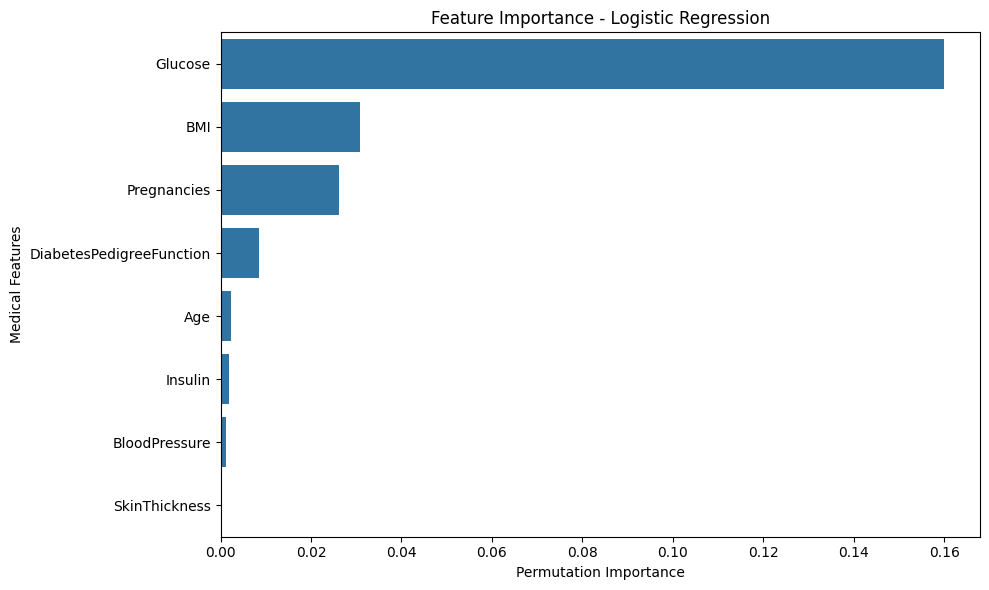

In [36]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate feature importance
importance = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='roc_auc'
)

# Create importance dataframe
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance.importances_mean
})

# Sort features
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display results
print("FEATURE IMPORTANCE ANALYSIS")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Logistic Regression')
plt.xlabel('Permutation Importance')
plt.ylabel('Medical Features')
plt.tight_layout()
plt.show()


In [37]:
# Model Performance Summary

model_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ]
})

print("DIABETES PREDICTION - MODEL PERFORMANCE")
display(model_results)

# Save results
model_results.to_csv(
    'diabetes_model_performance.csv',
    index=False
)

feature_importance.to_csv(
    'diabetes_feature_importance.csv',
    index=False
)

print("Reports saved successfully!")

DIABETES PREDICTION - MODEL PERFORMANCE


,Metric,Score
0,Accuracy,0.707792
1,Precision,0.600000
2,Recall,0.500000
3,F1 Score,0.545455
4,ROC-AUC,0.812963


Reports saved successfully!


In [38]:
# Random Forest Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

# Train model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_model.predict(X_test)

# Prediction probabilities
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate model
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

print("RANDOM FOREST MODEL PERFORMANCE")
print("--------------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

RANDOM FOREST MODEL PERFORMANCE
--------------------------------
Accuracy: 0.7468
Precision: 0.6415
Recall: 0.6296
F1 Score: 0.6355
ROC-AUC: 0.825

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81       100
           1       0.64      0.63      0.64        54

    accuracy                           0.75       154
   macro avg       0.72      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



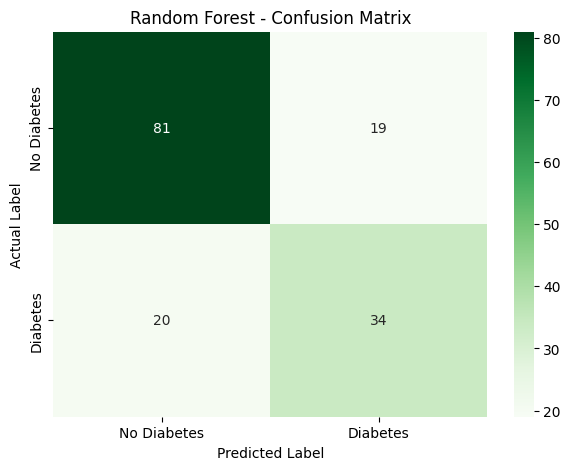

In [39]:
# Random Forest Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

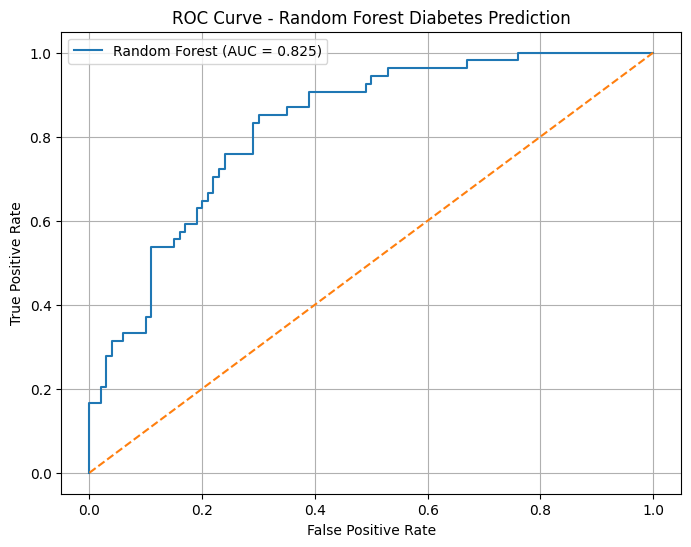

Random Forest ROC-AUC Score: 0.825


In [40]:
# Random Forest ROC Curve

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate probabilities
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
rf_fpr, rf_tpr, rf_thresholds = roc_curve(y_test, rf_prob)

# Calculate AUC
rf_auc = roc_auc_score(y_test, rf_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest Diabetes Prediction')

plt.legend()
plt.grid(True)
plt.show()

print("Random Forest ROC-AUC Score:", round(rf_auc, 4))

RANDOM FOREST FEATURE IMPORTANCE
                    Feature  Importance
1                   Glucose    0.273858
5                       BMI    0.171982
7                       Age    0.116258
6  DiabetesPedigreeFunction    0.110469
4                   Insulin    0.101164
2             BloodPressure    0.082892
3             SkinThickness    0.076534
0               Pregnancies    0.066843


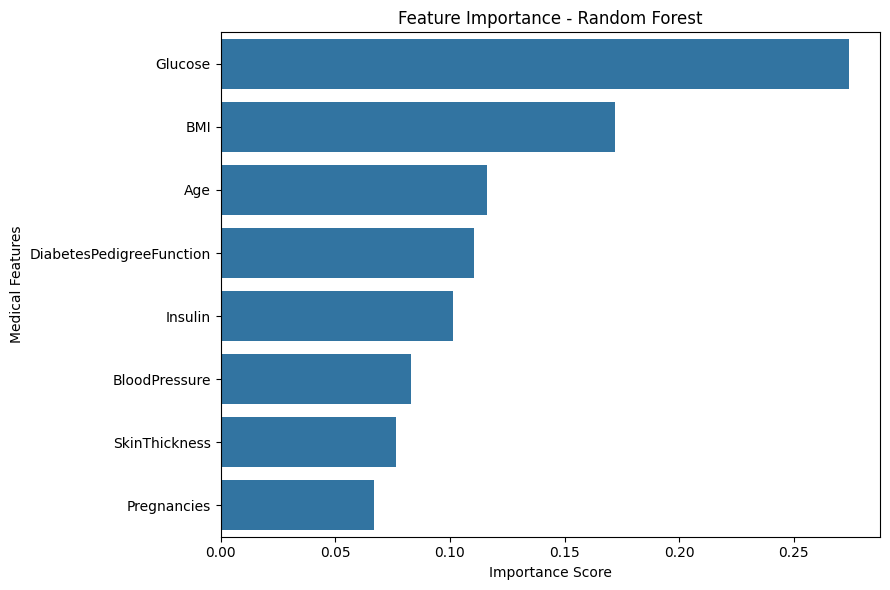

In [41]:
# Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort importance
rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
print(rf_importance)

# Plot feature importance
plt.figure(figsize=(9, 6))

sns.barplot(
    data=rf_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Medical Features')

plt.tight_layout()
plt.show()

In [42]:
# Model Comparison

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, y_pred),
        rf_accuracy
    ],

    'Precision': [
        precision_score(y_test, y_pred),
        rf_precision
    ],

    'Recall': [
        recall_score(y_test, y_pred),
        rf_recall
    ],

    'F1 Score': [
        f1_score(y_test, y_pred),
        rf_f1
    ],

    'ROC-AUC': [
        auc_score,
        rf_auc
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.813
1,Random Forest,0.7468,0.6415,0.6296,0.6355,0.825


In [43]:
# HYPERPARAMETER TUNING - RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Define parameter grid
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 5, 8, 10, 12, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Initialize Random Forest
rf_base = RandomForestClassifier(
    random_state=42,
    class_weight='balanced'
)

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized Search
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring='recall',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune
rf_search.fit(X_train, y_train)

# Best model
best_rf_model = rf_search.best_estimator_

print("BEST RANDOM FOREST PARAMETERS")
print(rf_search.best_params_)

print("\nBEST CROSS-VALIDATION RECALL:")
print(round(rf_search.best_score_, 4))

print("\nHyperparameter tuning completed!")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
BEST RANDOM FOREST PARAMETERS
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 5}

BEST CROSS-VALIDATION RECALL:
0.7288

Hyperparameter tuning completed!


In [44]:
# OPTIMIZED RANDOM FOREST MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predictions
rf_tuned_pred = best_rf_model.predict(X_test)
rf_tuned_prob = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("OPTIMIZED RANDOM FOREST PERFORMANCE")
print("--------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, rf_tuned_pred), 4))
print("Precision:", round(precision_score(y_test, rf_tuned_pred), 4))
print("Recall:", round(recall_score(y_test, rf_tuned_pred), 4))
print("F1 Score:", round(f1_score(y_test, rf_tuned_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_tuned_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, rf_tuned_pred))

print("\nBEST PARAMETERS")
print(rf_search.best_params_)

print("\nCROSS-VALIDATION RECALL")
print(round(rf_search.best_score_, 4))

OPTIMIZED RANDOM FOREST PERFORMANCE
--------------------------------------
Accuracy: 0.7597
Precision: 0.6308
Recall: 0.7593
F1 Score: 0.6891
ROC-AUC: 0.823

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.85      0.76      0.80       100
           1       0.63      0.76      0.69        54

    accuracy                           0.76       154
   macro avg       0.74      0.76      0.75       154
weighted avg       0.78      0.76      0.76       154


BEST PARAMETERS
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 5}

CROSS-VALIDATION RECALL
0.7288


In [45]:
{
    'n_estimators': 200,
    'min_samples_split': 5,
    'min_samples_leaf': 2,
    'max_features': 'log2',
    'max_depth': 5
}

{'n_estimators': 200,
 'min_samples_split': 5,
 'min_samples_leaf': 2,
 'max_features': 'log2',
 'max_depth': 5}

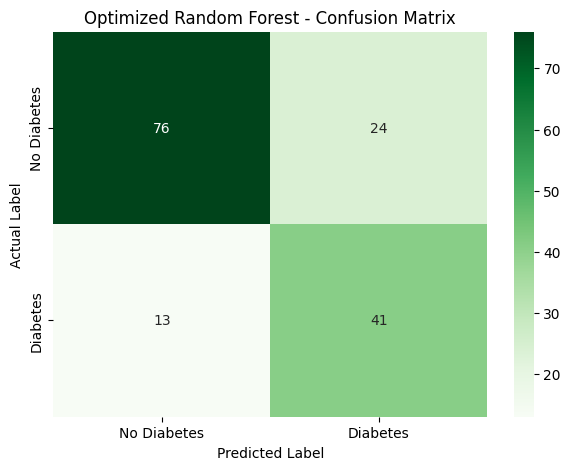

In [46]:
# OPTIMIZED RANDOM FOREST CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_tuned_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Optimized Random Forest - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [47]:
import joblib

# Check if the optimized model variable exists in current session and save it
if 'best_rf_model' in globals():
    joblib.dump(best_rf_model, 'diabetes_optimized_model.pkl')
    print("Optimized Diabetes Model (best_rf_model) Saved Successfully!")
elif 'rf_search' in globals():
    joblib.dump(rf_search.best_estimator_, 'diabetes_optimized_model.pkl')
    print("Optimized Diabetes Model (rf_search) Saved Successfully!")
else:
    print("Error: The optimized model variable is not found in memory.")
    print("Please run the hyperparameter tuning cell (cell xAB_lQcTX-1j) first to define the model.")

Optimized Diabetes Model (best_rf_model) Saved Successfully!


In [48]:
import pandas as pd
import numpy as np
import joblib
import os

# Validate if necessary files exist in the current session
if not os.path.exists('diabetes.csv'):
    print("Error: 'diabetes.csv' not found. Please upload it via cell X52W55-DSAaQ first.")
elif not os.path.exists('diabetes_optimized_model.pkl'):
    print("Error: 'diabetes_optimized_model.pkl' not found. Please run the training cells (down to Ht4GU-EHg-vU) to generate the model.")
else:
    # Load diabetes dataset
    df_diabetes = pd.read_csv('diabetes.csv')

    # Define features
    features = [
        'Pregnancies',
        'Glucose',
        'BloodPressure',
        'SkinThickness',
        'Insulin',
        'BMI',
        'DiabetesPedigreeFunction',
        'Age'
    ]

    # Replace invalid zero values
    zero_columns = [
        'Glucose',
        'BloodPressure',
        'SkinThickness',
        'Insulin',
        'BMI'
    ]

    df_model = df_diabetes.copy()
    df_model[zero_columns] = df_model[zero_columns].replace(0, np.nan)

    # Load optimized diabetes model
    model = joblib.load('diabetes_optimized_model.pkl')

    # Generate predictions
    X = df_model[features]
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    # Create patient prediction records
    diabetes_results = df_diabetes.copy()
    diabetes_results['Predicted_Diabetes'] = predictions
    diabetes_results['Diabetes_Probability'] = probabilities * 100

    diabetes_results['Predicted_Status'] = np.where(
        predictions == 1,
        'Diabetes',
        'No Diabetes'
    )

    diabetes_results['Actual_Status'] = np.where(
        diabetes_results['Outcome'] == 1,
        'Diabetes',
        'No Diabetes'
    )

    # Export CSV
    diabetes_results.to_csv(
        'diabetes_patient_predictions.csv',
        index=False
    )

    print("Diabetes Patient Prediction CSV generated successfully!")
    print("Total Patients:", len(diabetes_results))
    print(diabetes_results.head())

Diabetes Patient Prediction CSV generated successfully!
Total Patients: 768
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  Predicted_Diabetes  \
0                     0.627   50        1                   1   
1                     0.351   31        0                   0   
2                     0.672   32        1                   1   
3                     0.167   21        0                   0   
4                     2.288   33        1                   1   

   Diabetes_Probability Predicted_Status Actual_Status  
0             78.000081         Diabetes   

In [49]:
from google.colab import files
import os

file_path = 'diabetes_patient_predictions.csv'

if os.path.exists(file_path):
    files.download(file_path)
else:
    print(f"Error: {file_path} not found in the current directory.")
    print("Please execute cell 7huMYZzd0_5l first to generate the patient predictions file.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
import os

file_path = '/content/diabetes_patient_predictions.csv'

if os.path.exists(file_path):
    print("CSV file exists!")
    print("File size:", os.path.getsize(file_path), "bytes")
else:
    print("CSV file NOT found. We need to generate it first.")


CSV file exists!
File size: 55595 bytes


In [50]:
import pandas as pd
import numpy as np
import os
import urllib.request

# Define the destination path
dataset_path = '/content/processed.cleveland.data'

# Automatically download the dataset if it's not present
if not os.path.exists(dataset_path):
    print("Dataset not found. Downloading Cleveland Heart Disease dataset from UCI Repository...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    try:
        urllib.request.urlretrieve(url, dataset_path)
        print("Download completed successfully!")
    except Exception as e:
        print(f"Error downloading dataset: {e}")

columns = [
    'age', 'sex', 'cp', 'trestbps',
    'chol', 'fbs', 'restecg', 'thalach',
    'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

# Load the dataset
df_heart = pd.read_csv(
    dataset_path,
    names=columns,
    na_values='?'
)

print("\nHEART DISEASE DATASET Loaded Successfully!")
print(df_heart.head())

print("\nDataset Shape:")
print(df_heart.shape)

print("\nMissing Values:")
print(df_heart.isnull().sum())

print("\nTarget Distribution:")
print(df_heart['target'].value_counts())


HEART DISEASE DATASET Loaded Successfully!
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Dataset Shape:
(303, 14)

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target Distribution:
target
0    164
1     55
2     36
3    

In [51]:

# STEP 02: HEART DISEASE DATA CLEANING

# Check missing values
print("MISSING VALUES BEFORE CLEANING")
print(df_heart.isnull().sum())

# Convert columns to numeric
df_heart = df_heart.apply(pd.to_numeric, errors='coerce')

# Replace missing values using median
df_heart = df_heart.fillna(df_heart.median())

# Convert target into binary classification
df_heart['target'] = (df_heart['target'] > 0).astype(int)

# Check duplicate records
print("\nDuplicate Records:", df_heart.duplicated().sum())

# Remove duplicate records
df_heart = df_heart.drop_duplicates()

# Final dataset verification
print("\nCLEANED DATASET")
print(df_heart.head())

print("\nDataset Shape:", df_heart.shape)

print("\nMissing Values After Cleaning:")
print(df_heart.isnull().sum())

print("\nFinal Target Distribution:")
print(df_heart['target'].value_counts())

print("\nData Cleaning Completed Successfully!")


MISSING VALUES BEFORE CLEANING
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Duplicate Records: 0

CLEANED DATASET
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Dataset Shape: (303, 14)

Missing Values After Cleaning:
age         0
sex   

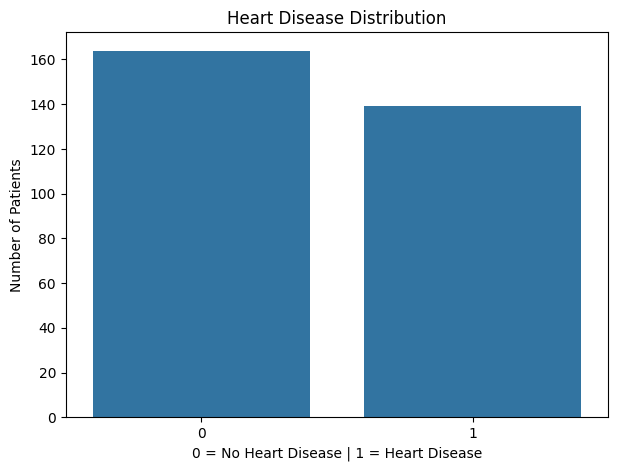

In [52]:

import matplotlib.pyplot as plt
import seaborn as sns

# Target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x='target',
    data=df_heart
)

plt.title('Heart Disease Distribution')
plt.xlabel('0 = No Heart Disease | 1 = Heart Disease')
plt.ylabel('Number of Patients')

plt.show()


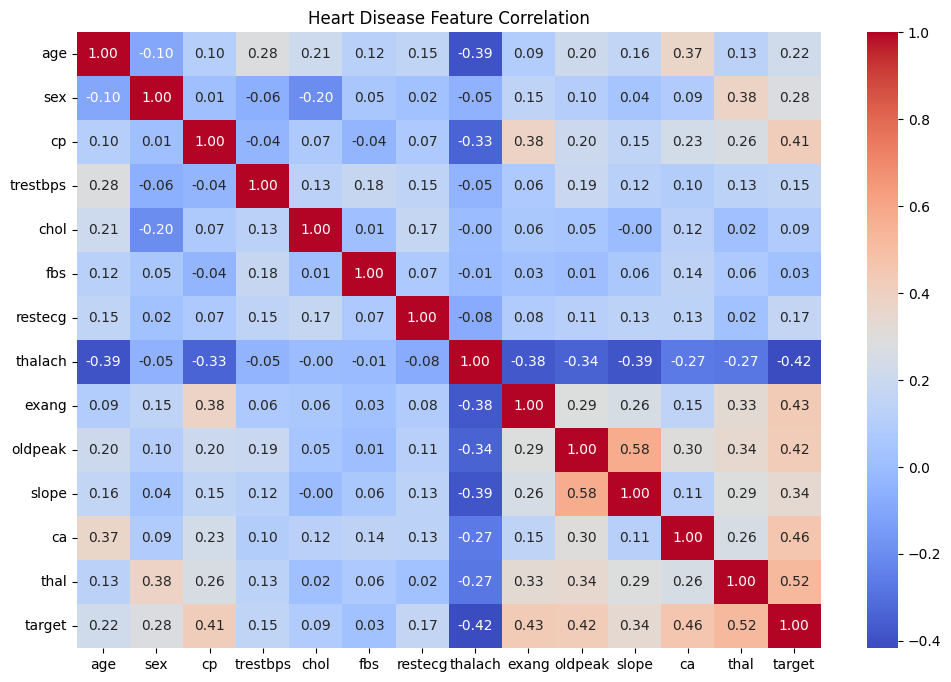

In [53]:

plt.figure(figsize=(12, 8))

correlation = df_heart.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Heart Disease Feature Correlation')

plt.show()


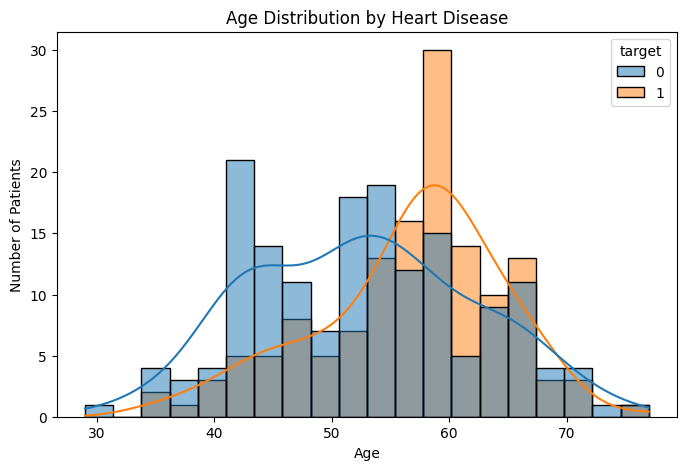

In [54]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_heart,
    x='age',
    hue='target',
    bins=20,
    kde=True
)

plt.title('Age Distribution by Heart Disease')
plt.xlabel('Age')
plt.ylabel('Number of Patients')

plt.show()


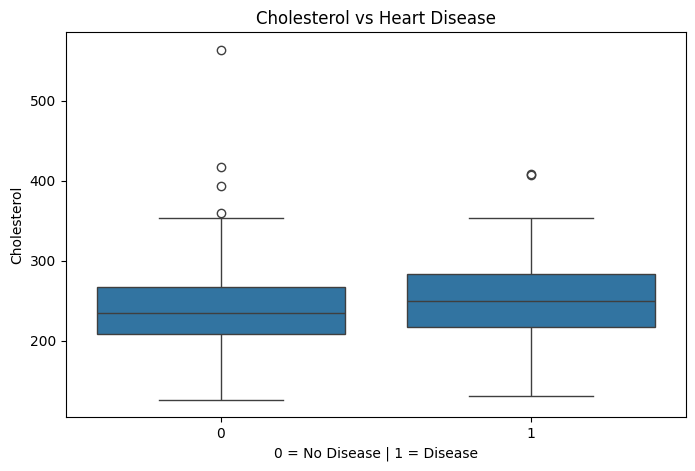

In [55]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_heart,
    x='target',
    y='chol'
)

plt.title('Cholesterol vs Heart Disease')
plt.xlabel('0 = No Disease | 1 = Disease')
plt.ylabel('Cholesterol')

plt.show()


In [56]:



from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df_heart.drop('target', axis=1)
y = df_heart['target']

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardization
scaler_heart = StandardScaler()

X_train_scaled = scaler_heart.fit_transform(X_train)
X_test_scaled = scaler_heart.transform(X_test)

# Display results
print("HEART DISEASE DATA SPLITTING")

print("\nTraining Features:", X_train_scaled.shape)
print("Testing Features:", X_test_scaled.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nFeature Scaling Completed Successfully!")


HEART DISEASE DATA SPLITTING

Training Features: (242, 13)
Testing Features: (61, 13)

Training Target: (242,)
Testing Target: (61,)

Training Target Distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing Target Distribution:
target
0    33
1    28
Name: count, dtype: int64

Feature Scaling Completed Successfully!


In [57]:

# STEP 05: LOGISTIC REGRESSION MODEL

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Initialize model
lr_heart = LogisticRegression(max_iter=1000)

# Train model
lr_heart.fit(X_train_scaled, y_train)

# Predictions
lr_pred = lr_heart.predict(X_test_scaled)
lr_prob = lr_heart.predict_proba(X_test_scaled)[:, 1]

# Performance metrics
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_auc = roc_auc_score(y_test, lr_prob)

# Display results
print("HEART DISEASE - LOGISTIC REGRESSION")

print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1 Score:", round(lr_f1, 4))
print("ROC-AUC:", round(lr_auc, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, lr_pred))


HEART DISEASE - LOGISTIC REGRESSION
Accuracy: 0.8689
Precision: 0.8125
Recall: 0.9286
F1 Score: 0.8667
ROC-AUC: 0.9513

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



In [58]:

# STEP 05 - RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    random_state=42,
    class_weight='balanced'
)

# Train Model
rf_model.fit(X_train_scaled, y_train)

# Predictions
rf_pred = rf_model.predict(X_test_scaled)
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Performance Metrics
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_auc = roc_auc_score(y_test, rf_prob)

# Display Results
print("HEART DISEASE - RANDOM FOREST")
print("--------------------------------")

print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, rf_pred))


HEART DISEASE - RANDOM FOREST
--------------------------------
Accuracy: 0.8852
Precision: 0.8387
Recall: 0.9286
F1 Score: 0.8814
ROC-AUC: 0.9567

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



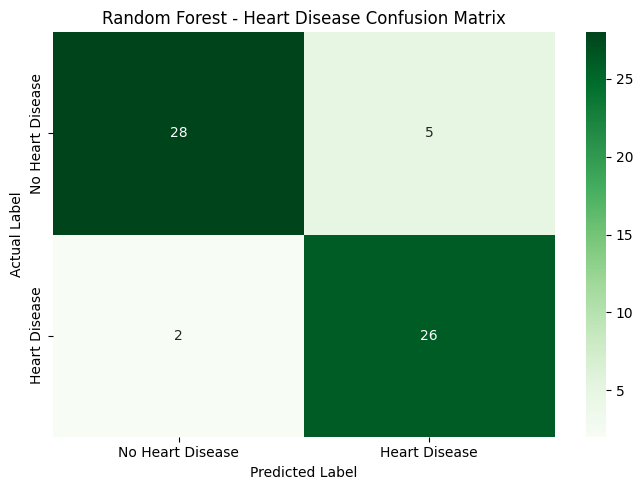

Confusion Matrix:
[[28  5]
 [ 2 26]]


In [59]:

# STEP 06 - RANDOM FOREST CONFUSION MATRIX

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Heart Disease', 'Heart Disease'],
    yticklabels=['No Heart Disease', 'Heart Disease']
)

plt.title('Random Forest - Heart Disease Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)


HEART DISEASE - FEATURE IMPORTANCE
     Feature  Importance
12      thal    0.192359
2         cp    0.139807
11        ca    0.118503
7    thalach    0.113559
9    oldpeak    0.091683
0        age    0.064981
8      exang    0.058785
4       chol    0.056222
3   trestbps    0.055319
10     slope    0.046240
1        sex    0.040291
6    restecg    0.014348
5        fbs    0.007903


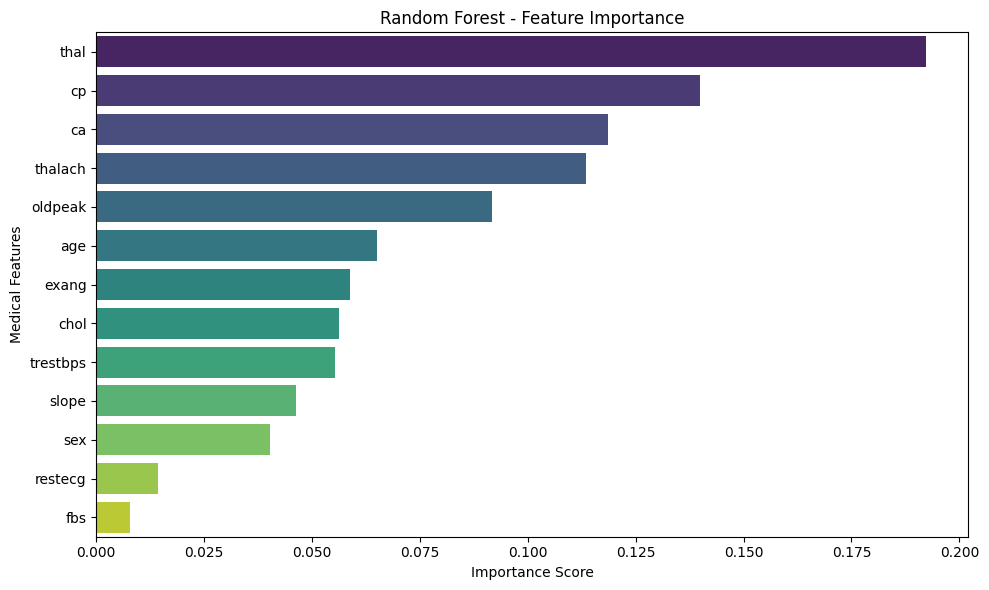

In [60]:

# STEP 07 - FEATURE IMPORTANCE ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("HEART DISEASE - FEATURE IMPORTANCE")
print(feature_importance)

# Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Medical Features')
plt.tight_layout()
plt.show()


HEART DISEASE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8689,0.8125,0.9286,0.8667,0.9513
1,Random Forest,0.8852,0.8387,0.9286,0.8814,0.9567


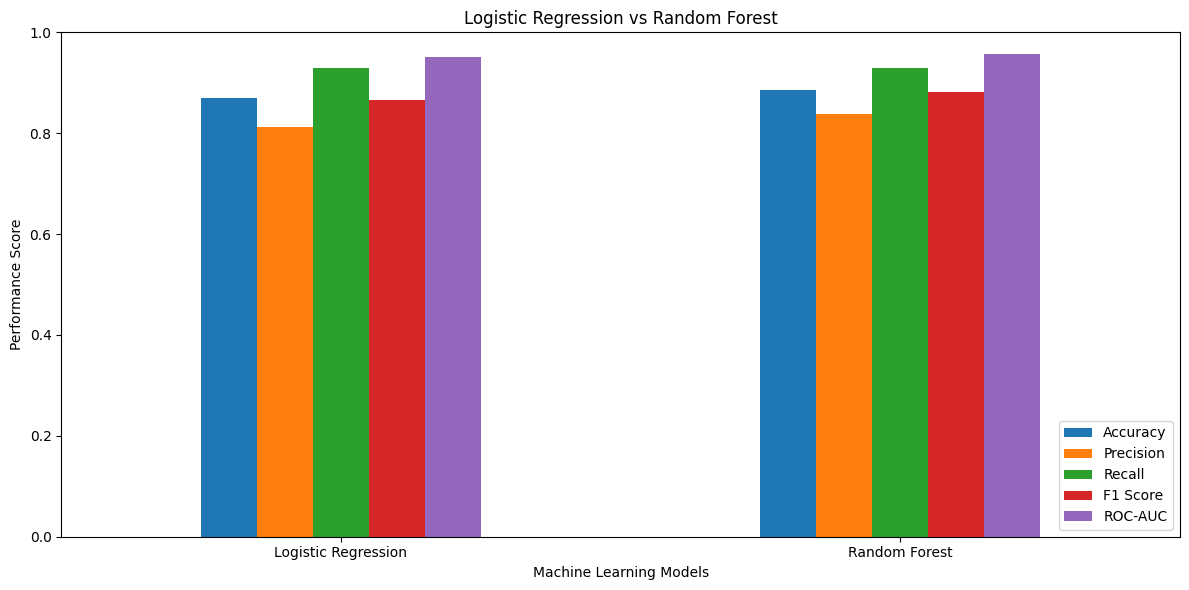

In [61]:

# STEP 08 - MODEL PERFORMANCE COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [lr_accuracy, rf_accuracy],
    'Precision': [lr_precision, rf_precision],
    'Recall': [lr_recall, rf_recall],
    'F1 Score': [lr_f1, rf_f1],
    'ROC-AUC': [lr_auc, rf_auc]
})

print("HEART DISEASE MODEL COMPARISON")
display(comparison.round(4))

# Visualization
comparison_plot = comparison.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Logistic Regression vs Random Forest')
plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Initialize Random Forest
rf = RandomForestClassifier(
    random_state=42,
    class_weight='balanced'
)

# Define parameters
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

# Hyperparameter tuning
rf_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

# Best model
rf_tuned = rf_search.best_estimator_

print("BEST PARAMETERS:")
print(rf_search.best_params_)

print("\nBEST CROSS-VALIDATION RECALL:")
print(round(rf_search.best_score_, 4))

print("\nHyperparameter Tuning Completed Successfully!")

Fitting 5 folds for each of 96 candidates, totalling 480 fits
BEST PARAMETERS:
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}

BEST CROSS-VALIDATION RECALL:
0.783

Hyperparameter Tuning Completed Successfully!


In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predictions
rf_tuned_pred = rf_tuned.predict(X_test)
rf_tuned_prob = rf_tuned.predict_proba(X_test)[:, 1]

# Performance metrics
print("OPTIMIZED RANDOM FOREST PERFORMANCE")
print("-----------------------------------")

print("Accuracy:", round(accuracy_score(y_test, rf_tuned_pred), 4))
print("Precision:", round(precision_score(y_test, rf_tuned_pred), 4))
print("Recall:", round(recall_score(y_test, rf_tuned_pred), 4))
print("F1 Score:", round(f1_score(y_test, rf_tuned_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_tuned_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, rf_tuned_pred))


OPTIMIZED RANDOM FOREST PERFORMANCE
-----------------------------------
Accuracy: 0.8852
Precision: 0.8387
Recall: 0.9286
F1 Score: 0.8814
ROC-AUC: 0.9556

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [64]:
# Check available variables
print([name for name in globals() if 'scal' in name.lower()])

['StandardScaler', 'scaler_heart', 'X_train_scaled', 'X_test_scaled']


In [65]:
import joblib

# Save optimized Random Forest model
joblib.dump(rf_tuned, 'heart_disease_optimized_model.pkl')

# Save the scaler
joblib.dump(scaler_heart, 'heart_disease_scaler.pkl')

# Save feature names
joblib.dump(list(X_train.columns), 'heart_disease_features.pkl')

print("Heart Disease Model Saved Successfully!")
print("Scaler Saved Successfully!")
print("Feature Names Saved Successfully!")

Heart Disease Model Saved Successfully!
Scaler Saved Successfully!
Feature Names Saved Successfully!


In [66]:
from google.colab import files

files.download('heart_disease_optimized_model.pkl')
files.download('heart_disease_scaler.pkl')
files.download('heart_disease_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Prepare prediction dataset
powerbi_data = X_test.copy()

powerbi_data['Actual_Disease'] = y_test.values
powerbi_data['Predicted_Disease'] = rf_tuned_pred
powerbi_data['Disease_Probability'] = rf_tuned_prob

powerbi_data['Actual_Status'] = powerbi_data['Actual_Disease'].map({
    0: 'No Heart Disease',
    1: 'Heart Disease'
})

powerbi_data['Predicted_Status'] = powerbi_data['Predicted_Disease'].map({
    0: 'No Heart Disease',
    1: 'Heart Disease'
})

# 2. Save prediction dataset
powerbi_data.to_csv('Heart_Disease_Predictions.csv', index=False)

# 3. Model performance dataset
metrics_data = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Score': [
        accuracy_score(y_test, rf_tuned_pred),
        precision_score(y_test, rf_tuned_pred),
        recall_score(y_test, rf_tuned_pred),
        f1_score(y_test, rf_tuned_pred),
        roc_auc_score(y_test, rf_tuned_prob)
    ]
})

metrics_data.to_csv('Model_Performance.csv', index=False)

# 4. Feature importance dataset
importance_data = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_tuned.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_data.to_csv('Feature_Importance.csv', index=False)

print("POWER BI DATASETS CREATED SUCCESSFULLY!")
print("Prediction Records:", len(powerbi_data))
print("Model Performance Records:", len(metrics_data))
print("Feature Importance Records:", len(importance_data))

POWER BI DATASETS CREATED SUCCESSFULLY!
Prediction Records: 61
Model Performance Records: 5
Feature Importance Records: 13


In [68]:
from google.colab import files

files.download('Heart_Disease_Predictions.csv')
files.download('Model_Performance.csv')
files.download('Feature_Importance.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>